# 08 - ALTA10: Farm-wide, wake-aware SCADA screening (first pass)

**Purpose:** prioritize measurement/operational investigation, not diagnose a
broken anemometer. No LiDAR values or previous WTG159 findings enter the rules.
The existing 07 Jensen equations, candidate Ct, and terrain-height geometry
are retained. Only the targets are expanded to all coordinate-listed sites.

NEW, EXPLORATORY DESIGN (not established findings or manufacturer limits):
- Each site has three fixed nearby peers selected by distance and ground height.
- Target and all three peers must be observed simultaneously, generating by a
  power-range proxy, with low predicted wakes at every tested direction offset.
- Learn the early-period median target-minus-peer relationship by mast sector
  and speed bin. Look for sustained later departures, not just different speeds.
- Also report persistent raw peer differences and near-flat wind signals.
- Power-curve errors are descriptive only and NEVER set the priority label.

IMPORTANT: an early baseline is NOT verified healthy. Persistent errors can be
absorbed by it; raw peer differences are retained for that reason. Fixed peers
are not calibrated references. Terrain, channel processing, changing operating
states, and shared sensor errors can affect results. This is retrospective
screening, not an untouched holdout test, a failure probability, or certification.

Save beside 07 in notebooks/alex_notebooks/. Raw and previous outputs are read
only. This run writes a new timestamped folder under data/processed/08_scada_screening/.

## 1. Settings - freeze these before inspecting the output
All screening cutoffs below are first-pass research choices. Do not tune them
just to make WTG159 receive a flag. A low-coverage site is not declared healthy.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj.to_string(index=False) if hasattr(obj, 'to_string') else obj)

CONFIG = {
    'project_root': None,
    'fallback_root': r'C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project',
    'scada_file': 'data/processed/scada_data.parquet',
    'mast_file': 'data/processed/metmasts_data.parquet',
    'start_date': '2026-05-01',
    'end_date_exclusive': None,  # None: use available overlapping observations.
    'baseline_fraction_of_calendar_days': 0.60,
    'evaluation_start': None,   # Optional YYYY-MM-DD; overrides the fraction.
    'power_unit': 'kW',         # Explicit units; never guessed from magnitude.
    'mast_speed_column': 'mm_wind_speed_3',
    'mast_direction_column': 'mm_wind_direction_3',
    'mast_speed_min': 7.0,
    'mast_speed_max': 10.0,
    'wake_limit_pct': 2.0,
    'direction_offsets': [-10, -5, 0, 5, 10],
    'scada_speed_min': 3.0,
    'scada_speed_max': 25.0,
    'power_min_kw': 100.0,
    'power_max_kw': 2850.0,
    # Optional SPONSOR-VERIFIED status column / allowed values, not guessed.
    'operating_status_column': None,
    'allowed_operating_statuses': None,
    'peer_count': 3,
    'peer_max_distance_km': 3.0,
    'peer_max_ground_height_difference_m': 75.0,
    'baseline_min_records_per_cell': 30,
    'baseline_min_days_per_cell': 5,
    'min_evaluation_records': 200,
    'min_evaluation_days': 10,
    'min_scored_fraction_of_peer_pairs': 0.50,
    'min_scada_record_coverage': 0.50,
    'departure_floor_ms': 1.0,
    'departure_robust_scale_multiplier': 3.0,
    'departure_min_consecutive_records': 3,  # Consecutive 10-minute labels.
    'priority_min_flagged_days': 3,
    'priority_min_departure_fraction': 0.05,
    'persistent_peer_difference_ms': 1.0,
    'persistent_peer_same_direction_fraction': 0.70,
    'flat_window_records': 6,  # Six consecutive 10-minute averages.
    'flat_target_range_ms': 0.02,
    'flat_peer_range_min_ms': 1.0,
    'flat_power_range_min_kw': 200.0,
    'run_power_context': True,
    'save_interval_data': True,
    'show_plots': True,
    'max_diagnostic_plots': 3,
}

# IDENTICAL candidate wake parameters to 07, not OEM-verified or fitted here.
ROTOR_DIAMETER_M = 103.0
HUB_HEIGHT_M = 85.0
FREE_STREAM_SPEED = 8.2
BASELINE_K = 0.05
CT_SPEEDS = np.array([3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 12.5, 14, 16, 18, 20, 25.0])
CT_POINTS = np.array([.95, .92, .88, .83, .80, .77, .70, .58,
                      .44, .31, .25, .16, .11, .08, .06, .03])
KNOWN_LIDAR_SITES = {'WTG159', 'WTG170', 'WTG171', 'WTG173', 'WTG180', 'WTG184'}
PRIORITY_ORDER = {
    'Priority investigation': 0,
    'Monitor / context required': 1,
    'Insufficient evidence': 2,
    'No strong anomaly in assessed conditions': 3,
}
STEP = pd.Timedelta(minutes=10)

## 2. Loading and validation
Timestamps are assumed UTC, as in 07. No clock shifting, interpolation, duplicate
averaging, or fill-forward is used. Missing source times remain missing.

In [2]:
def normalize_id(value):
    """Map known GE/WTG/numeric turbine IDs to WTG<number>.

    Examples: GE-150, WTG150, WTG_T150, and 150.0 -> WTG150.
    Unknown formats still raise an error rather than guessing an identity.
    """
    if pd.isna(value):
        return pd.NA

    text = str(value).strip().upper()
    match = re.fullmatch(
        r"(?:(?:WTG[_\s-]*T?|GE)[_\s-]*)?(\d+)(?:\.0)?",
        text,
    )
    if match is None:
        raise ValueError(f"Unrecognized turbine identifier: {value!r}")

    return f"WTG{int(match.group(1))}"


def root_folder(cfg):
    if cfg['project_root'] is not None:
        root = Path(cfg['project_root']).expanduser().resolve()
        if not (root / 'data').is_dir():
            raise FileNotFoundError(f'No data/ folder beneath {root}')
        return root
    seeds = [Path.cwd()]
    if '__file__' in globals():
        seeds.insert(0, Path(__file__).resolve().parent)
    for seed in seeds:
        for p in (seed, *seed.parents):
            if (p / cfg['scada_file']).exists():
                return p
    root = Path(cfg['fallback_root'])
    if (root / cfg['scada_file']).exists():
        return root
    raise FileNotFoundError('Put 08 in notebooks/alex_notebooks/ or set CONFIG["project_root"].')


def unique_file(root, filename, required=True):
    hits = sorted((root / 'data').rglob(filename))
    if len(hits) == 1:
        return hits[0]
    if len(hits) > 1:
        raise ValueError(f'Multiple copies of {filename}; resolve ambiguity: {hits}')
    if required:
        raise FileNotFoundError(f'No {filename} beneath {root / "data"}')
    return None


def read_table(path):
    if not path.is_file():
        raise FileNotFoundError(path)
    if path.suffix.lower() == '.csv':
        return pd.read_csv(path, low_memory=False)
    if path.suffix.lower() == '.parquet':
        return pd.read_parquet(path)
    raise ValueError(f'Expected CSV or Parquet, not {path.suffix}')


def normalize_time(df, name, audit):
    df = df.copy()
    if not df.columns.is_unique:
        raise ValueError(f'{name}: duplicate column names.')
    if 'timestamp' not in df.columns and 'utc' not in df.columns:
        df = df.reset_index()
    col = next((c for c in ['timestamp', 'utc'] if c in df.columns), None)
    if col is None:
        raise KeyError(f'{name}: need timestamp or utc; got {list(df.columns)}')
    if pd.api.types.is_numeric_dtype(df[col]):
        raise ValueError(f'{name}: numeric timestamps require explicit epoch units; not guessed.')
    df['timestamp'] = pd.to_datetime(df[col], errors='coerce', utc=True)
    bad = df.timestamp.isna()
    audit.append({'dataset': name, 'check': 'invalid_timestamp_rows', 'count': int(bad.sum())})
    df = df.loc[~bad].copy()
    if (df.timestamp != df.timestamp.dt.floor('10min')).any():
        raise ValueError(f'{name}: timestamps not on 10-minute labels. Check conventions; no rounding applied.')
    return df


def assert_unique(df, keys, name):
    dup = df.duplicated(keys, keep=False)
    if dup.any():
        raise ValueError(f'{name}: duplicate keys; do not average them.\n{df.loc[dup, keys].head(8)}')


def load_inputs(root, cfg):
    audit = []
    s = normalize_time(read_table(root / cfg['scada_file']), 'SCADA', audit)
    if 'turbine' not in s and 'turbine' in s.index.names:
        s = s.reset_index()
    required = ['turbine', 'wind_speed', 'real_power_ac']
    missing = set(required) - set(s.columns)
    if missing:
        raise KeyError(f'SCADA columns missing {missing}. The script uses 07\'s processed schema.')
    s['turbine'] = s.turbine.map(normalize_id)
    audit.append({'dataset': 'SCADA', 'check': 'missing_turbine_id', 'count': int(s.turbine.isna().sum())})
    s = s.dropna(subset=['turbine']).copy()
    assert_unique(s, ['timestamp', 'turbine'], 'SCADA')
    for col in ['wind_speed', 'real_power_ac', 'air_density']:
        if col not in s:
            s[col] = np.nan
        s[col] = pd.to_numeric(s[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
    unit_scale = {'kW': 1., 'W': .001, 'MW': 1000.}
    if cfg['power_unit'] not in unit_scale:
        raise ValueError('power_unit must explicitly be kW, W, or MW.')
    s['power_kw'] = s.real_power_ac * unit_scale[cfg['power_unit']]
    status = cfg['operating_status_column']
    columns = ['timestamp', 'turbine', 'wind_speed', 'power_kw', 'air_density']
    if status is not None:
        if status not in s or not cfg['allowed_operating_statuses']:
            raise ValueError('Provide a valid status column and sponsor-confirmed allowed values.')
        columns.append(status)
    s = s[columns].copy()
    m = normalize_time(read_table(root / cfg['mast_file']), 'Mast', audit)
    assert_unique(m, ['timestamp'], 'Mast')
    for col in [cfg['mast_speed_column'], cfg['mast_direction_column']]:
        if col not in m:
            raise KeyError(f'Mast column missing: {col}')
        m[col] = pd.to_numeric(m[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
    m = m[['timestamp', cfg['mast_speed_column'], cfg['mast_direction_column']]].rename(
        columns={cfg['mast_speed_column']: 'mast_speed', cfg['mast_direction_column']: 'mast_direction'}
    )
    if s.empty or m.empty:
        raise ValueError('No timestamped SCADA or mast records.')
    start = max(s.timestamp.min().floor('D'), m.timestamp.min().floor('D'))
    if cfg['start_date']:
        start = max(start, pd.Timestamp(cfg['start_date'], tz='UTC'))
    end = min(s.timestamp.max(), m.timestamp.max()) + STEP
    if cfg['end_date_exclusive']:
        end = min(end, pd.Timestamp(cfg['end_date_exclusive'], tz='UTC'))
    if end <= start:
        raise ValueError('No overlapping dates for the requested period.')
    s = s.loc[s.timestamp.ge(start) & s.timestamp.lt(end)].copy()
    m = m.loc[m.timestamp.ge(start) & m.timestamp.lt(end)].copy()
    idx = pd.date_range(start, end, freq='10min', inclusive='left', name='timestamp')
    days = idx.normalize().unique()
    if len(days) < 3:
        raise ValueError('Need more than two calendar days for early/later screening.')
    if cfg['evaluation_start']:
        split = pd.Timestamp(cfg['evaluation_start'], tz='UTC')
    else:
        k = int(np.floor(len(days) * cfg['baseline_fraction_of_calendar_days']))
        split = days[min(max(k, 1), len(days) - 1)]
    if not start < split < end:
        raise ValueError('Evaluation start must be strictly inside the analysis period.')
    return s, m, idx, split, audit

## 3. Unchanged Jensen physics, now at every coordinate-listed turbine
Source: 07 hub_predictions_at_direction. Identical D=103 m, hub height=85 m,
k=.05, U=8.2 m/s, candidate Ct interpolation, height separation, quadratic
combination, and 100% deficit cap. All upstream turbines remain assumed active.
A fixed hub-center model is NOT rotor/LiDAR-volume wake reconstruction.

In [3]:
def candidate_ct(u):
    a = np.asarray(u, dtype=float)
    result = np.interp(a, CT_SPEEDS, CT_POINTS)
    result = np.where((a < 4.) | (a >= 25.), 0., result)
    return float(result) if result.ndim == 0 else result


def load_geometry(root):
    from pyproj import Transformer
    import rasterio
    from rasterio.warp import transform
    path = unique_file(root, 'turbine_coordinate_ALTA10.csv')
    farm = pd.read_csv(path)
    need = {'Turbine_ID', 'Latitude', 'Longitude'}
    if not need.issubset(farm):
        raise KeyError(f'Coordinate file must contain {need}')
    farm['turbine'] = farm.Turbine_ID.map(normalize_id)
    if farm.turbine.isna().any():
        raise ValueError('Missing IDs in farm geometry.')
    assert_unique(farm, ['turbine'], 'Coordinates')
    for col in ['Latitude', 'Longitude']:
        farm[col] = pd.to_numeric(farm[col], errors='coerce')
    if not (farm.Latitude.between(-90, 90) & farm.Longitude.between(-180, 180)).all():
        raise ValueError('Invalid farm coordinates.')
    farm = farm[['turbine', 'Latitude', 'Longitude']].sort_values('turbine').reset_index(drop=True)
    tr = Transformer.from_crs('EPSG:4326', 'EPSG:32611', always_xy=True)
    farm['x'], farm['y'] = tr.transform(farm.Longitude.to_numpy(), farm.Latitude.to_numpy())
    dem = unique_file(root, 'elevation.tif')
    with rasterio.open(dem) as src:
        if src.crs is None:
            raise ValueError('DEM has no coordinate reference system.')
        x, y = transform('EPSG:32611', src.crs, farm.x.tolist(), farm.y.tolist())
        vals = list(src.sample(zip(x, y), masked=True))
        farm['elevation_m'] = [float(v[0]) if not np.ma.is_masked(v[0]) else np.nan for v in vals]
    if not np.isfinite(farm.elevation_m).all():
        raise ValueError('DEM does not cover every turbine. No flat-terrain substitution used.')
    return farm, path, dem


def all_jensen_predictions(farm):
    x, y, z = [farm[c].to_numpy() for c in ['x', 'y', 'elevation_m']]
    # Matrix rows are targets, columns are sources. Self-wakes have along=0.
    ex, ey, vert = x[:, None] - x[None, :], y[:, None] - y[None, :], z[:, None] - z[None, :]
    ct = candidate_ct(FREE_STREAM_SPEED)
    results = []
    for angle in np.arange(0, 360, 5):
        theta = np.deg2rad(angle)
        dx, dy = -np.sin(theta), -np.cos(theta)
        along = ex * dx + ey * dy
        across = -ex * dy + ey * dx
        positive = np.maximum(along, 0)
        radius = ROTOR_DIAMETER_M / 2 + BASELINE_K * positive
        center = (1 - np.sqrt(1 - ct)) / (1 + 2 * BASELINE_K * positive / ROTOR_DIAMETER_M)**2
        delta = np.where((along > 0) & (np.hypot(across, vert) <= radius), center, 0.)
        loss = 100 * np.minimum(1., np.sqrt((delta**2).sum(axis=1)))
        results.extend({'turbine': t, 'wind_from_deg': int(angle), 'predicted_deficit_pct': float(d)}
                       for t, d in zip(farm.turbine, loss))
    return pd.DataFrame(results)


def assign_wake_grid(mast_aligned, names, lookup, cfg):
    table = lookup.pivot(index='wind_from_deg', columns='turbine', values='predicted_deficit_pct')
    table = table.reindex(index=np.arange(0, 360, 5), columns=names)
    if not np.isfinite(table.to_numpy()).all():
        raise ValueError('Incomplete directional lookup.')
    direction = mast_aligned.mast_direction
    valid = direction.between(0, 360)
    safe = direction.where(valid, 0).to_numpy()
    offset_predictions = []
    for offset in cfg['direction_offsets']:
        k = (np.floor(((safe + offset) % 360 + 2.5) / 5).astype(int) % 72)
        offset_predictions.append(table.to_numpy()[k, :])
    maximum = np.maximum.reduce(offset_predictions)
    maximum[~valid.to_numpy(), :] = np.nan
    return pd.DataFrame(maximum, index=mast_aligned.index, columns=names)


def fixed_peer_sets(farm, available_ids, cfg):
    rows, sets = [], {}
    for t in farm.itertuples():
        c = farm.loc[(farm.turbine != t.turbine) & farm.turbine.isin(available_ids)].copy()
        c['distance_km'] = np.hypot(c.x - t.x, c.y - t.y) / 1000
        c['ground_difference_m'] = (c.elevation_m - t.elevation_m).abs()
        c = c.loc[(c.distance_km <= cfg['peer_max_distance_km']) &
                  (c.ground_difference_m <= cfg['peer_max_ground_height_difference_m'])]
        c = c.sort_values(['distance_km', 'turbine']).head(cfg['peer_count'])
        sets[t.turbine] = c.turbine.tolist()
        for rank, p in enumerate(c.itertuples(), 1):
            rows.append({'turbine': t.turbine, 'peer': p.turbine, 'rank': rank,
                         'distance_km': p.distance_km, 'ground_height_difference_m': p.ground_difference_m})
    return sets, pd.DataFrame(rows, columns=['turbine','peer','rank','distance_km','ground_height_difference_m'])

## 4. Baselines and episode rules
Baseline cells: 30-degree mast sectors x 1 m/s mast-speed bins. Baselines use
only the earlier dates. No fallback for unsupported conditions: mark unassessed.
A sustained departure is >=3 consecutive 10-minute labels of the SAME sign,
beyond max(1 m/s, 3 * 1.4826 * baseline median absolute deviation).
A near-flat candidate needs six consecutive eligible labels with target speed
range <=0.02 m/s, peer-median range >=1 m/s, AND target power range >=200 kW.
Missing times or eligibility failures break runs. Thresholds are exploratory.

In [4]:
def sustained(mask, min_records):
    a = np.asarray(mask, dtype=bool)
    edges = np.diff(np.r_[False, a, False].astype(int))
    starts, ends = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)
    result = np.zeros(len(a), dtype=bool)
    for first, stop in zip(starts, ends):
        if stop - first >= min_records:
            result[first:stop] = True
    return result


def episodes(flag, frame, turbine, kind):
    a = np.asarray(flag, dtype=bool)
    edges = np.diff(np.r_[False, a, False].astype(int))
    out = []
    for first, stop in zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)):
        g = frame.iloc[first:stop]
        out.append({'turbine': turbine, 'reason': kind,
                    'first_timestamp_label_utc': str(g.index[0]),
                    'last_timestamp_label_utc': str(g.index[-1]),
                    'records': len(g), 'nominal_minutes': 10 * len(g),
                    'mean_scada_ms': g.wind_speed.mean(), 'mean_peer_ms': g.peer_speed.mean(),
                    'mean_raw_peer_difference_ms': g.peer_difference_ms.mean(),
                    'mean_adjusted_residual_ms': g.adjusted_residual_ms.mean(),
                    'peer_ids': g.peer_ids.iloc[0]})
    return out


def fit_baseline(frame, split, cfg):
    train = frame.loc[(frame.index < split) & frame.peer_difference_ms.notna()].copy()
    train['day'] = train.index.normalize()
    rows = []
    for (sector, speed_bin), g in train.groupby(['sector', 'speed_bin'], observed=True):
        n, days = len(g), g.day.nunique()
        med = g.peer_difference_ms.median()
        mad = (g.peer_difference_ms - med).abs().median()
        supported = n >= cfg['baseline_min_records_per_cell'] and days >= cfg['baseline_min_days_per_cell']
        rows.append({'sector': int(sector), 'speed_bin': int(speed_bin),
                     'baseline_n': n, 'baseline_days': days, 'baseline_supported': supported,
                     'baseline_difference_ms': med,
                     'departure_limit_ms': max(cfg['departure_floor_ms'],
                         cfg['departure_robust_scale_multiplier'] * 1.4826 * mad)})
    cols = ['sector','speed_bin','baseline_n','baseline_days','baseline_supported',
            'baseline_difference_ms','departure_limit_ms']
    return pd.DataFrame(rows, columns=cols)


def analyze_turbine(frame, turbine, split, cfg):
    b = fit_baseline(frame, split, cfg)
    mapped = frame.reset_index().merge(b, on=['sector','speed_bin'], how='left', validate='many_to_one')
    g = mapped.set_index('timestamp').sort_index()
    supported = g.baseline_supported.eq(True)
    g['adjusted_residual_ms'] = (g.peer_difference_ms - g.baseline_difference_ms).where(supported)
    later = g.index >= split
    scored = later & g.adjusted_residual_ms.notna().to_numpy()
    up = scored & g.adjusted_residual_ms.gt(g.departure_limit_ms).fillna(False).to_numpy()
    down = scored & g.adjusted_residual_ms.lt(-g.departure_limit_ms).fillna(False).to_numpy()
    up = sustained(up, cfg['departure_min_consecutive_records'])
    down = sustained(down, cfg['departure_min_consecutive_records'])
    g['departure_episode'] = up | down
    # A fixed full time grid ensures rolling windows cannot jump missing times.
    eligible = later & g.peer_difference_ms.notna().to_numpy()
    w = cfg['flat_window_records']
    own = g.wind_speed.where(eligible)
    peer = g.peer_speed.where(eligible)
    power = g.power_kw.where(eligible)
    own_range = own.rolling(w, min_periods=w).max() - own.rolling(w, min_periods=w).min()
    peer_range = peer.rolling(w, min_periods=w).max() - peer.rolling(w, min_periods=w).min()
    power_range = power.rolling(w, min_periods=w).max() - power.rolling(w, min_periods=w).min()
    endpoints = (own_range.le(cfg['flat_target_range_ms']) &
                 peer_range.ge(cfg['flat_peer_range_min_ms']) &
                 power_range.ge(cfg['flat_power_range_min_kw'])).fillna(False).to_numpy()
    flat = np.zeros(len(g), dtype=bool)
    for end in np.flatnonzero(endpoints):
        flat[end - w + 1:end + 1] = True
    g['flat_episode'] = flat
    event_rows = (episodes(up, g, turbine, 'Sustained positive baseline departure') +
                  episodes(down, g, turbine, 'Sustained negative baseline departure') +
                  episodes(flat, g, turbine, 'Near-flat wind despite changing peers and power'))
    ev = g.loc[later]
    paired = ev.peer_difference_ms.dropna()
    n_pair = len(paired)
    pair_days = paired.index.normalize().nunique()
    n_score = int(scored.sum())
    score_days = g.index[scored].normalize().nunique()
    supported_fraction = n_score / n_pair if n_pair else np.nan
    record_coverage = ev.record_present.mean() if len(ev) else 0.
    adequate_peer = (n_pair >= cfg['min_evaluation_records'] and pair_days >= cfg['min_evaluation_days']
                     and record_coverage >= cfg['min_scada_record_coverage'])
    adequate_score = (adequate_peer and n_score >= cfg['min_evaluation_records']
                      and score_days >= cfg['min_evaluation_days']
                      and supported_fraction >= cfg['min_scored_fraction_of_peer_pairs'])
    departure_days = g.index[g.departure_episode].normalize().nunique()
    flat_days = g.index[flat].normalize().nunique()
    departure_fraction = int(g.departure_episode.sum()) / n_score if n_score else np.nan
    raw_limit = cfg['persistent_peer_difference_ms']
    raw_positive_fraction = paired.gt(raw_limit).mean() if n_pair else np.nan
    raw_negative_fraction = paired.lt(-raw_limit).mean() if n_pair else np.nan
    raw_watch = bool(adequate_peer and max(raw_positive_fraction, raw_negative_fraction) >=
                     cfg['persistent_peer_same_direction_fraction'])
    reasons = []
    if g.departure_episode.any():
        reasons.append('Later-period baseline-departure episodes')
    if flat.any():
        reasons.append('Near-flat signal with variable peers/power')
    if raw_watch:
        reasons.append('Persistent raw peer difference: terrain/processing not resolved')
    if not adequate_score:
        reasons.append('Incomplete supported-condition coverage')
    if record_coverage < cfg['min_scada_record_coverage']:
        reasons.append('Low SCADA timestamp coverage')
    high_departure = (adequate_score and departure_days >= cfg['priority_min_flagged_days'] and
                      departure_fraction >= cfg['priority_min_departure_fraction'])
    high_flat = adequate_peer and flat_days >= cfg['priority_min_flagged_days']
    if high_departure or high_flat:
        label = 'Priority investigation'
    elif not adequate_peer:
        label = 'Insufficient evidence'
    elif g.departure_episode.any() or flat.any() or raw_watch:
        label = 'Monitor / context required'
    elif not adequate_score:
        label = 'Insufficient evidence'
    else:
        label = 'No strong anomaly in assessed conditions'
    result = {
        'turbine': turbine, 'screening_label': label,
        'reasons': '; '.join(reasons) or 'No implemented rule triggered',
        'fixed_peer_ids': g.peer_ids.iloc[0],
        'known_lidar_site': turbine in KNOWN_LIDAR_SITES, # Annotation only, never a predictor.
        'evaluation_peer_pairs': n_pair, 'evaluation_peer_days': int(pair_days),
        'evaluation_scored_records': n_score, 'evaluation_scored_days': int(score_days),
        'supported_condition_pct': 100 * supported_fraction,
        'scada_record_coverage_pct': 100 * record_coverage,
        'median_raw_peer_difference_ms': paired.median(),
        'mean_raw_peer_difference_ms': paired.mean(),
        'raw_positive_over_limit_pct': 100 * raw_positive_fraction,
        'raw_negative_over_limit_pct': 100 * raw_negative_fraction,
        'mean_adjusted_residual_ms': ev.adjusted_residual_ms.mean(),
        'departure_records': int(g.departure_episode.sum()),
        'departure_days': int(departure_days), 'departure_pct_of_scored': 100 * departure_fraction,
        'flat_records': int(flat.sum()), 'flat_days': int(flat_days),
        'insufficient_fixed_peers': bool(g.peer_ids.iloc[0].count('|') + 1 < cfg['peer_count'])
            if g.peer_ids.iloc[0] else True,
    }
    b.insert(0, 'turbine', turbine)
    g.insert(0, 'turbine', turbine)
    g['period'] = np.where(g.index < split, 'early_baseline', 'later_evaluation')
    return result, event_rows, b, g

## 5. Power consistency is CONTEXT, not a priority trigger
Uses the same GE reference file, normal TI and density 1.02 kg/m^3. Apply a
narrow measured-density screen (.99-1.05), NOT a density correction. No inferred
power units or wind speed from power. SCADA wind-speed provenance is unverified.
A good match may be circular if reported wind speed is processed from power.

In [5]:
def reference_curve(root, cfg):
    if not cfg['run_power_context']:
        return None
    path = unique_file(root, 'GE_2_85MW_103mRD_PC.csv', required=False)
    if path is None:
        warnings.warn('Manufacturer curve absent: power-context table will be unassessed.')
        return None
    ref = pd.read_csv(path)
    ref.columns = ref.columns.str.strip()
    need = ['WINDSPEED','POWER_KW','AIR_DENSITY','TI_CLASS']
    if not set(need).issubset(ref):
        warnings.warn('Reference schema not as expected: power context skipped, no inferred curve.')
        return None
    for c in ['WINDSPEED','POWER_KW','AIR_DENSITY']:
        ref[c] = pd.to_numeric(ref[c], errors='coerce')
    ref = ref.loc[np.isclose(ref.AIR_DENSITY, 1.02, atol=.001) &
                  ref.TI_CLASS.astype(str).str.strip().str.lower().eq('normal')].copy()
    if 'TURBINE_MODEL' in ref and ref.TURBINE_MODEL.nunique() > 1:
        raise ValueError('Reference has multiple turbine models; select the correct curve explicitly.')
    ref = ref[['WINDSPEED','POWER_KW']].dropna().sort_values('WINDSPEED')
    if len(ref) < 2 or ref.WINDSPEED.duplicated().any():
        raise ValueError('Reference curve missing or has duplicate wind speeds; do not average curves.')
    return ref


def power_context(frame, turbine, split, ref):
    out = {'turbine': turbine, 'power_context_n': 0, 'power_context_days': 0,
           'mean_power_error_kw': np.nan, 'power_rmse_kw': np.nan,
           'power_context_status': 'Not assessed: reference/density/data unavailable'}
    if ref is None:
        return out
    g = frame.loc[(frame.index >= split) & frame.target_eligible &
                  frame.wind_speed.between(5, 12.5) & frame.air_density.between(.99, 1.05) &
                  frame.wind_speed.between(ref.WINDSPEED.min(), ref.WINDSPEED.max())].copy()
    if g.empty:
        return out
    err = np.interp(g.wind_speed, ref.WINDSPEED, ref.POWER_KW) - g.power_kw
    out.update(power_context_n=len(g), power_context_days=g.index.normalize().nunique(),
               mean_power_error_kw=float(err.mean()), power_rmse_kw=float(np.sqrt(np.mean(err**2))),
               power_context_status='Descriptive only; NOT used for label or independent sensor validation')
    return out

## 6. Outputs and first-pass priority rules
Priority: adequate coverage AND either sustained departures on >=3 days and
>=5% of supported evaluation records, OR near-flat candidate intervals on >=3 days.
Monitor: some departure/flat episodes or persistent raw peer difference with adequate pairs.
Insufficient: too few peers, observations/days, baseline support, or input coverage.
Otherwise: no strong anomaly IN ASSESSED CONDITIONS, not healthy/correct.
These thresholds are heuristic and NOT an industry fault standard.

In [6]:
def plot_outputs(summary, frames, split, outdir, cfg):
    def finish(fig, name):
        fig.tight_layout()
        fig.savefig(outdir / name, dpi=180, bbox_inches='tight')
        if cfg['show_plots']:
            plt.show()
        plt.close(fig)
    ranked = summary.loc[summary.evaluation_peer_pairs > 0].copy()
    if not ranked.empty:
        ranked = ranked.sort_values('median_raw_peer_difference_ms')
        fig, ax = plt.subplots(figsize=(11, max(5, len(ranked) * .23)))
        ax.scatter(ranked.median_raw_peer_difference_ms, np.arange(len(ranked)), s=28)
        ax.axvline(0, linestyle='--', linewidth=1)
        ax.set_yticks(np.arange(len(ranked)), ranked.turbine)
        ax.set(xlabel='Median SCADA minus fixed-peer median (m/s)',
               title='Later-period raw peer differences - geography is not calibrated out')
        ax.grid(axis='x', alpha=.25)
        finish(fig, '08_raw_peer_differences.png')
    fig, ax = plt.subplots(figsize=(11, 4.5))
    counts = summary.screening_label.value_counts().reindex(PRIORITY_ORDER, fill_value=0)
    ax.bar(np.arange(len(counts)), counts.to_numpy())
    ax.set_xticks(np.arange(len(counts)), ['Priority investigation','Monitor / context','Insufficient evidence','No strong anomaly\nin assessed conditions'])
    ax.set(ylabel='Number of turbines', title='Exploratory SCADA screening - NOT a fault classification')
    ax.grid(axis='y', alpha=.25)
    finish(fig, '08_screening_label_counts.png')
    selected = summary.loc[summary.screening_label.isin(['Priority investigation','Monitor / context required'])]
    selected = selected.head(cfg['max_diagnostic_plots'])
    for row in selected.itertuples():
        if row.turbine not in frames:
            continue
        g = frames[row.turbine]
        fig, ax = plt.subplots(figsize=(13, 4.5))
        daily = g.assign(day=g.index.normalize(),
                         baseline_plot=g.baseline_difference_ms.where(g.baseline_supported.eq(True))).groupby('day').agg(
            mean_difference=('peer_difference_ms','mean'), baseline=('baseline_plot','mean'))
        if not daily.empty:
            daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max(), freq='D'))
        ax.plot(daily.index, daily.mean_difference, marker='.', label='Daily mean target minus peers')
        ax.plot(daily.index, daily.baseline, linestyle='--', label='Mapped early-period baseline')
        ax.axvline(split, linestyle=':', label='Later evaluation begins')
        ax.set(xlabel='UTC day', ylabel='Wind-speed difference (m/s)',
               title=f'{row.turbine} | {row.screening_label} - inspect episode CSV, not just this daily plot')
        ax.legend(fontsize=8); ax.grid(alpha=.25)
        fig.autofmt_xdate()
        finish(fig, f'08_{row.turbine}_daily_context.png')


def write_notes(outdir, cfg, split, source_files):
    notes = f'''ALTA10 08 - FIRST-PASS SCREENING, NOT A CALIBRATION OR FAULT DIAGNOSIS

What changed from 07: all coordinate-listed turbines can be screening targets.
What did not change: Jensen U=8.2 m/s, k=.05, candidate Ct=.756, D=103 m,
identical assumed 85 m hub heights, terrain elevation differences, root-sum-square
wake combination, 5-degree lookup, and all upstream turbines assumed active.
The mast is a provisional input, NOT local ground truth. It is not screened for
its own rotor-height wake exposure here. No LiDAR measurements enter labels.

Later evaluation begins: {split}. Earlier dates estimate the baseline.
This is a retrospective chronological comparison, NOT an untouched test set.
No healthy baseline or true anemometer-failure labels have been established.

Fixed peers: closest {cfg['peer_count']} coordinate-neighbors having SCADA,
within {cfg['peer_max_distance_km']} km and {cfg['peer_max_ground_height_difference_m']} m
of ground elevation. Target excluded. ALL peers must pass at the SAME timestamp;
there is no substitution if one is missing/ineligible. Ground height is not sensor
height, and proximity is not proof of equal wind. Same fixed peer set is used
before/after the split. Shared peer faults can mask or create apparent anomalies.

Baseline: median(target SCADA - peer median) in each 30-degree mast-direction
sector x 1 m/s mast-speed bin, fitted ONLY on earlier dates. Require at least
{cfg['baseline_min_records_per_cell']} records and {cfg['baseline_min_days_per_cell']} days.
Unsupported later conditions are not scored. Do not choose criteria after seeing
which turbine is flagged. This baseline can absorb persistent historical bias;
raw peer differences remain in the table and may trigger MONITOR, never confirmed bias.

An episode is not an independent event count. Timestamp labels remain unverified.
Near-flat episodes require consecutive eligible rows with changing peers AND power.
Power-range eligibility does not establish uncurtailed, fault-free operation.
Power-curve errors are optional descriptive context, NOT a priority trigger.
No bootstrap p-values, failure probabilities, or classification accuracy are claimed.

The outputs cover only the screened conditions (mast 7-10 m/s by default).
The June 8 high-wind LiDAR episode may be outside that scope and may not appear.
No strong anomaly means only no implemented rule triggered in assessed conditions.
Missing data or sparse sectors can lead to INSUFFICIENT rather than a clean result.

Run provenance and every threshold are in 08_run_settings.json.
The 47-turbine file may omit upstream turbines outside the modeled farm boundary.
Treat edge turbines and uncertain direction/height conventions with extra caution.

References for method/API context (not validation of our thresholds):
https://pandas.pydata.org/docs/reference/api/pandas.merge.html
https://sklearn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html
https://wes.copernicus.org/articles/8/893/2023/
The cited paper discusses SCADA normal-behavior monitoring, largely temperatures;
it does not validate this anemometer screening system.
'''
    (outdir / '08_INTERPRETATION.txt').write_text(notes, encoding='utf-8')
    provenance = {'config': cfg, 'evaluation_start_utc': str(split), 'sources': source_files,
                  'wake': {'U_ms':FREE_STREAM_SPEED,'k':BASELINE_K,'Ct':candidate_ct(FREE_STREAM_SPEED),
                           'D_m':ROTOR_DIAMETER_M,'hub_height_assumed_m':HUB_HEIGHT_M,
                           'CT_SPEEDS':CT_SPEEDS.tolist(),'CT_POINTS':CT_POINTS.tolist()},
                  'pandas_version':pd.__version__, 'numpy_version':np.__version__}
    (outdir / '08_run_settings.json').write_text(json.dumps(provenance, indent=2, default=str), encoding='utf-8')

## 7. Run the complete screening
Keep the existing project data unchanged. Inspect coverage and peers BEFORE
interpreting priorities. First return the review table and label-count plot.

Project root: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project
Output folder: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\08_scada_screening\run_20261029T040948431080Z
47 coordinate-listed turbines; 47 SCADA IDs in requested dates.
Early baseline: 2026-05-01 00:00:00+00:00 through labels before 2026-07-31 00:00:00+00:00
Later retrospective evaluation: 2026-07-31 00:00:00+00:00 through 2026-09-29 06:50:00+00:00
  01/47 WTG150: Monitor / context required; later pairs=1,037; scored=1,026
  02/47 WTG151: No strong anomaly in assessed conditions; later pairs=1,037; scored=1,026
  03/47 WTG152: Monitor / context required; later pairs=1,040; scored=1,029
  04/47 WTG153: No strong anomaly in assessed conditions; later pairs=1,435; scored=1,410
  05/47 WTG154: No strong anomaly in assessed conditions; later pairs=1,556; scored=1,523
  06/47 WTG155: No strong anomaly in assessed conditions; later pairs=1,556; scored=1,523
  07/47 WTG156: No strong anom

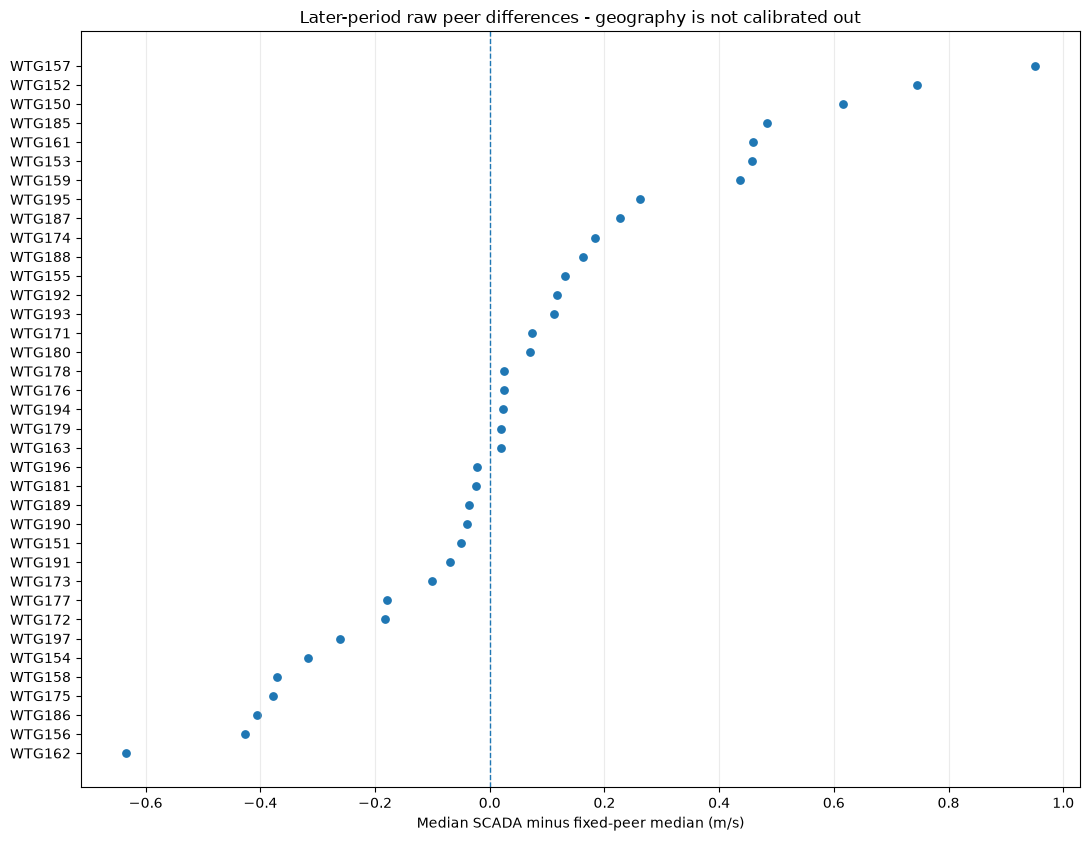

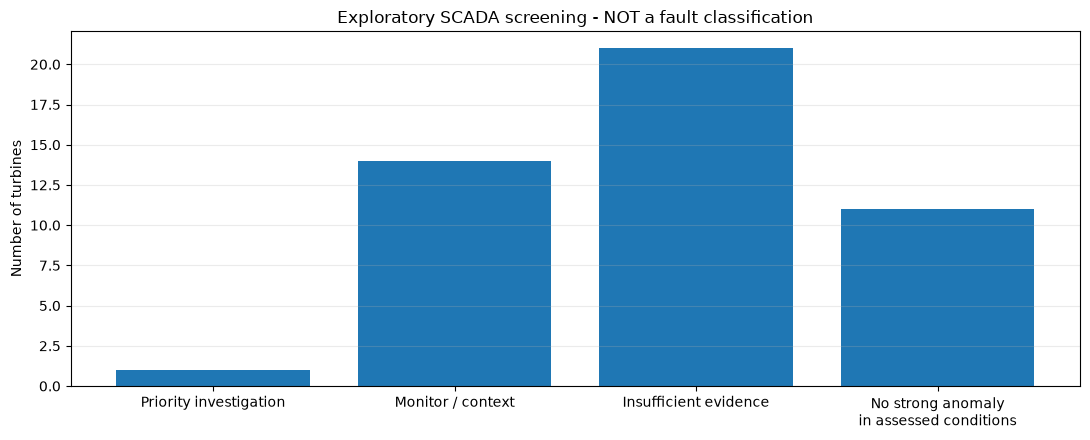

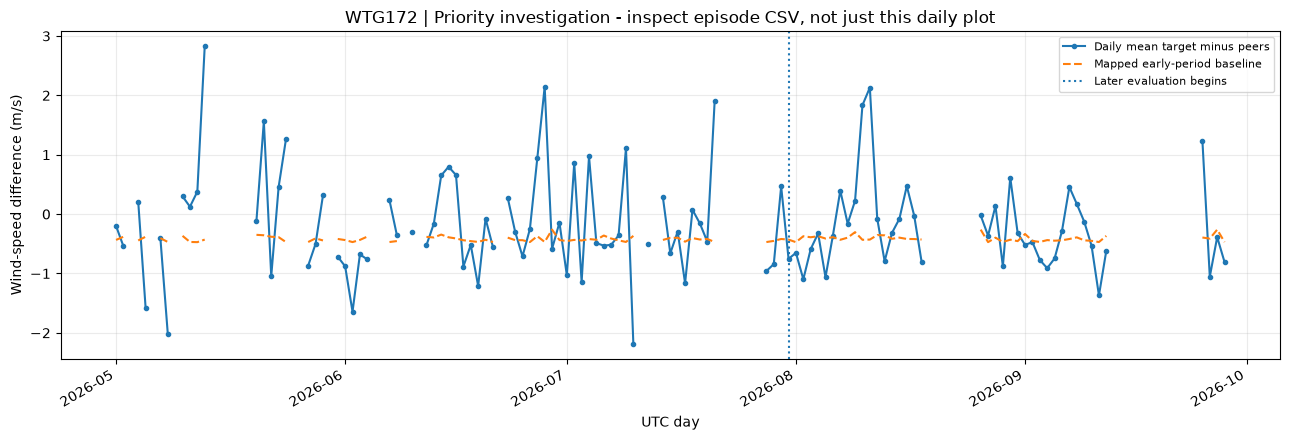

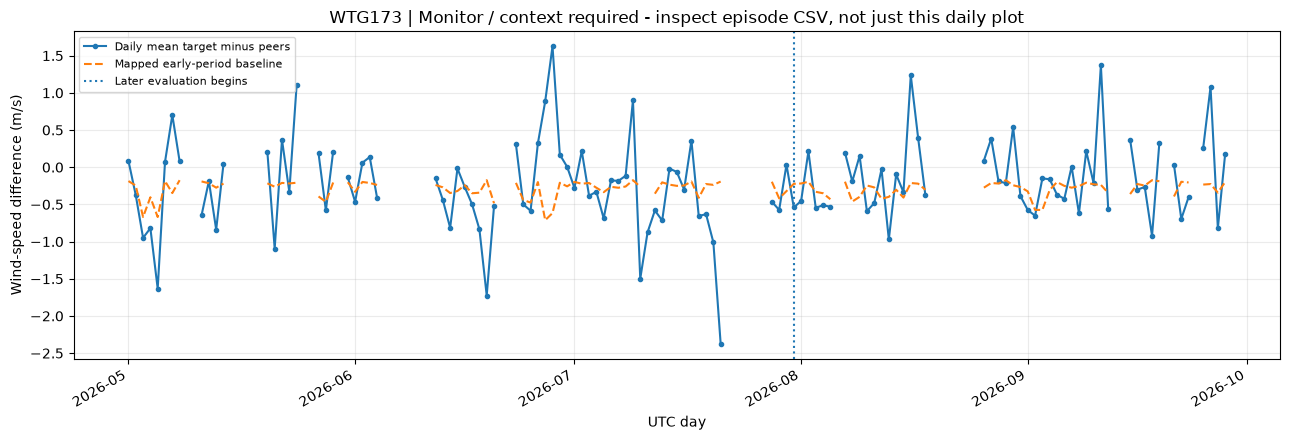

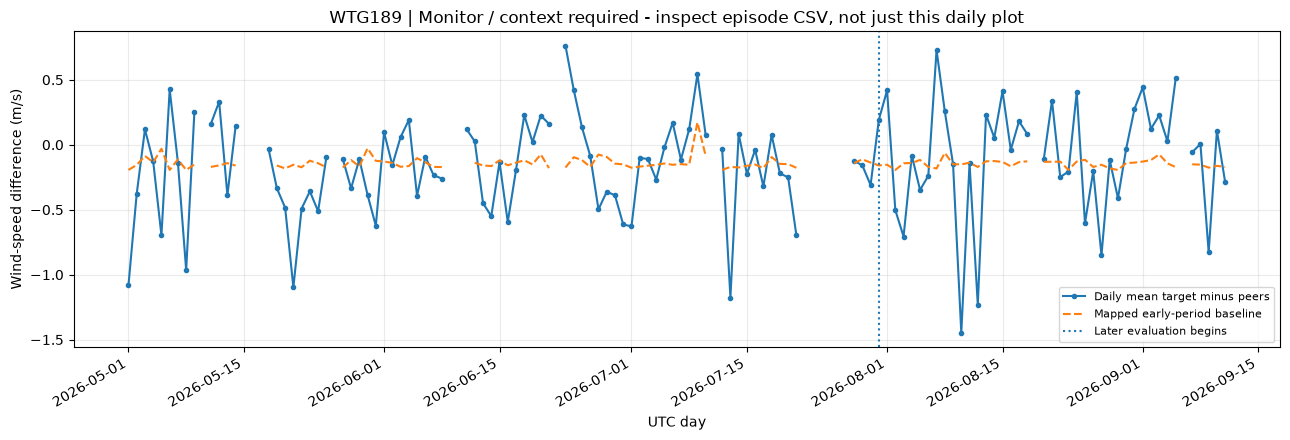


FIRST-PASS INVESTIGATION TABLE - not faulty/healthy labels


,turbine,screening_label,fixed_peer_ids,evaluation_peer_pairs,evaluation_scored_records,supported_condition_pct,departure_days,flat_days,reasons
21,WTG172,Priority investigation,WTG171|WTG173|WTG170,1088,1039,95.496,3,0,Later-period baseline-departure episodes
22,WTG173,Monitor / context required,WTG172|WTG174|WTG171,1379,1359,98.550,3,0,Later-period baseline-departure episodes
38,WTG189,Monitor / context required,WTG190|WTG188|WTG191,962,958,99.584,3,0,Later-period baseline-departure episodes
40,WTG191,Monitor / context required,WTG192|WTG190|WTG189,925,920,99.459,3,0,Later-period baseline-departure episodes
2,WTG152,Monitor / context required,WTG153|WTG151|WTG154,1040,1029,98.942,2,0,Later-period baseline-departure episodes
8,WTG158,Monitor / context required,WTG157|WTG159|WTG156,1314,1293,98.402,2,0,Later-period baseline-departure episodes
20,WTG171,Monitor / context required,WTG172|WTG170|WTG173,1088,1039,95.496,2,0,Later-period baseline-departure episodes
23,WTG174,Monitor / context required,WTG173|WTG175|WTG172,1315,1295,98.479,2,0,Later-period baseline-departure episodes
24,WTG175,Monitor / context required,WTG176|WTG174|WTG173,1407,1383,98.294,2,0,Later-period baseline-departure episodes
39,WTG190,Monitor / context required,WTG189|WTG191|WTG192,925,920,99.459,2,0,Later-period baseline-departure episodes



Review coverage and peer selections before interpreting priority.
Power consistency is context only. WTG159 is not forced to be flagged.
Saved: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\08_scada_screening\run_20261029T040948431080Z


In [7]:
def run_screening(config=None):
    cfg = dict(CONFIG if config is None else config)
    if not (0 < cfg['baseline_fraction_of_calendar_days'] < 1):
        raise ValueError('Baseline fraction must be between 0 and 1.')
    if cfg['peer_count'] < 3:
        raise ValueError('Use at least three fixed peers for this median-based first pass.')
    if cfg['mast_speed_min'] != 7 or cfg['mast_speed_max'] != 10:
        raise ValueError('This version is designed for mast speed 7-10 m/s; revise bins explicitly to expand it.')
    root = root_folder(cfg)
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    outdir = root / 'data' / 'processed' / '08_scada_screening' / ('run_' + stamp)
    outdir.mkdir(parents=True, exist_ok=False)
    print('Project root:', root)
    print('Output folder:', outdir)
    s, mast, idx, split, audit = load_inputs(root, cfg)
    farm, coord_path, dem_path = load_geometry(root)
    names = farm.turbine.tolist()
    print(f'{len(farm)} coordinate-listed turbines; {s.turbine.nunique()} SCADA IDs in requested dates.')
    unknown = sorted(set(s.turbine) - set(names))
    pd.DataFrame({'scada_id_without_geometry': unknown}).to_csv(outdir / '08_unmapped_scada_ids.csv', index=False)
    if unknown:
        warnings.warn(f'{len(unknown)} SCADA IDs have no farm coordinates and are not wake-screened; see CSV.')
    s = s.loc[s.turbine.isin(names)].copy()
    if s.empty:
        raise ValueError('No SCADA IDs match farm coordinates.')
    lookup = all_jensen_predictions(farm)
    lookup.to_csv(outdir / '08_jensen_all_turbines.csv', index=False)
    farm.to_csv(outdir / '08_turbine_geometry.csv', index=False)
    m = mast.set_index('timestamp').reindex(idx)
    wake = assign_wake_grid(m, names, lookup, cfg)
    valid_dir = m.mast_direction.between(0, 360)
    m.loc[valid_dir, 'mast_direction'] %= 360
    m.loc[~valid_dir, 'mast_direction'] = np.nan
    speed = s.pivot(index='timestamp', columns='turbine', values='wind_speed').reindex(index=idx, columns=names)
    power = s.pivot(index='timestamp', columns='turbine', values='power_kw').reindex(index=idx, columns=names)
    density = s.pivot(index='timestamp', columns='turbine', values='air_density').reindex(index=idx, columns=names)
    records = s.assign(record_present=True).pivot(index='timestamp', columns='turbine', values='record_present')
    records = records.reindex(index=idx, columns=names).eq(True)
    eligible = (speed.ge(cfg['scada_speed_min']) & speed.le(cfg['scada_speed_max']) &
                power.ge(cfg['power_min_kw']) & power.le(cfg['power_max_kw']) &
                wake.lt(cfg['wake_limit_pct']))
    eligible = eligible.mul(m.mast_speed.between(cfg['mast_speed_min'], cfg['mast_speed_max']), axis=0).astype(bool)
    status = cfg['operating_status_column']
    if status is not None:
        states = s.pivot(index='timestamp', columns='turbine', values=status).reindex(index=idx, columns=names)
        eligible &= states.isin(cfg['allowed_operating_statuses'])
    peers, peer_table = fixed_peer_sets(farm, set(s.turbine), cfg)
    peer_table.to_csv(outdir / '08_fixed_peers.csv', index=False)
    sector = (np.floor(((m.mast_direction + 15) % 360) / 30)).astype('Int64')
    speed_bin = np.floor(m.mast_speed - 7).clip(0, 2).where(m.mast_speed.between(7, 10)).astype('Int64')
    ref = reference_curve(root, cfg)
    results, events, baseline_tables, coverage_rows, power_rows = [], [], [], [], []
    frames = {}
    print(f'Early baseline: {idx[0]} through labels before {split}')
    print(f'Later retrospective evaluation: {split} through {idx[-1]}')
    for number, t in enumerate(names, 1):
        p = peers[t]
        can_pair = eligible[t].copy()
        if len(p) != cfg['peer_count']:
            can_pair[:] = False
            peer_speed = pd.Series(np.nan, index=idx)
        else:
            can_pair &= eligible[p].all(axis=1)
            # All fixed peers must be present. Do not silently compute a smaller median.
            peer_speed = speed[p].median(axis=1, skipna=False).where(can_pair)
        frame = pd.DataFrame({'wind_speed': speed[t], 'power_kw': power[t], 'air_density': density[t],
                              'peer_speed': peer_speed, 'mast_speed': m.mast_speed,
                              'mast_direction': m.mast_direction,
                              'offset_max_deficit_pct':wake[t], 'sector':sector, 'speed_bin':speed_bin,
                              'record_present':records[t], 'target_eligible':eligible[t],
                              'peer_ids':'|'.join(p)}, index=idx)
        frame['peer_difference_ms'] = (frame.wind_speed - frame.peer_speed).where(can_pair)
        result, ev, base, full = analyze_turbine(frame, t, split, cfg)
        results.append(result); events.extend(ev); baseline_tables.append(base)
        power_rows.append(power_context(frame, t, split, ref))
        observed = s.loc[s.turbine.eq(t)]
        coverage_rows.append({'turbine':t, 'coordinate_available':True,
                              'scada_rows':len(observed), 'expected_time_slots':len(idx),
                              'scada_record_pct':100 * len(observed) / len(idx),
                              'missing_wind_rows':int(observed.wind_speed.isna().sum()),
                              'missing_power_rows':int(observed.power_kw.isna().sum()),
                              'negative_wind_rows':int(observed.wind_speed.lt(0).sum()),
                              'above_50_ms_rows':int(observed.wind_speed.gt(50).sum()),
                              'fixed_peers_found':len(p), 'eligible_target_rows':int(eligible[t].sum()),
                              'simultaneous_peer_rows':int(can_pair.sum())})
        # Retain just analyzable rows for compact output; gaps never linked as episodes.
        compact = full.loc[full.peer_difference_ms.notna()].copy()
        frames[t] = compact
        if cfg['save_interval_data']:
            (outdir / 'intervals').mkdir(exist_ok=True)
            compact.reset_index().to_csv(outdir / 'intervals' / f'{t}_screened_intervals.csv', index=False)
        print(f'  {number:02d}/{len(names)} {t}: {result["screening_label"]}; '
              f'later pairs={result["evaluation_peer_pairs"]:,}; scored={result["evaluation_scored_records"]:,}')
    summary = pd.DataFrame(results)
    summary['_order'] = summary.screening_label.map(PRIORITY_ORDER)
    summary = summary.sort_values(['_order','departure_days','flat_days','turbine'], ascending=[True,False,False,True]).drop(columns='_order')
    event_columns = ['turbine','reason','first_timestamp_label_utc','last_timestamp_label_utc','records',
                     'nominal_minutes','mean_scada_ms','mean_peer_ms','mean_raw_peer_difference_ms',
                     'mean_adjusted_residual_ms','peer_ids']
    event_table = pd.DataFrame(events, columns=event_columns)
    summary.to_csv(outdir / '08_turbine_review_table.csv', index=False)
    event_table.to_csv(outdir / '08_flagged_episodes.csv', index=False)
    pd.concat(baseline_tables, ignore_index=True).to_csv(outdir / '08_early_condition_baselines.csv', index=False)
    pd.DataFrame(coverage_rows).to_csv(outdir / '08_data_coverage.csv', index=False)
    pd.DataFrame(power_rows).to_csv(outdir / '08_power_context_ONLY.csv', index=False)
    pd.DataFrame(audit).to_csv(outdir / '08_input_audit.csv', index=False)
    write_notes(outdir, cfg, split, [str(root/cfg['scada_file']), str(root/cfg['mast_file']), str(coord_path), str(dem_path)])
    plot_outputs(summary, frames, split, outdir, cfg)
    print('\nFIRST-PASS INVESTIGATION TABLE - not faulty/healthy labels')
    with pd.option_context('display.max_rows', None, 'display.max_columns', None,
                           'display.max_colwidth', 110):
        display(summary[['turbine','screening_label','fixed_peer_ids','evaluation_peer_pairs',
                         'evaluation_scored_records','supported_condition_pct','departure_days','flat_days','reasons']].round(3))
    print('\nReview coverage and peer selections before interpreting priority.')
    print('Power consistency is context only. WTG159 is not forced to be flagged.')
    print('Saved:', outdir)
    return {'summary':summary, 'events':event_table, 'coverage':pd.DataFrame(coverage_rows),
            'power_context':pd.DataFrame(power_rows), 'output_dir':outdir, 'evaluation_start':split}


if __name__ == '__main__':
    screening_results = run_screening()